# **Лабораторна робота № 10**
**Тема:** Файлове введення-виведення та збереження стану за допомогою менеджерів контексту.

**Мета:** Опанувати практичні навички проектування підсистем персистентного збереження даних, файлового введення-виведення та серіалізації структур інформації мовою Python. Навчитися здійснювати потокове читання, фільтрацію та запис текстових файлів через контекстні менеджери `with`, освоїти структурний парсинг і генерацію звітів у форматах CSV (модуль `csv`) та JSON (модуль `json`). Опанувати низькорівневе бінарне позиціонування файлового курсору за допомогою методів `seek()` і `tell()`, а також реалізувати валідацію апаратних бінарних файлів за магічними сигнатурами (magic numbers) у задачах комп'ютерної інженерії.

**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

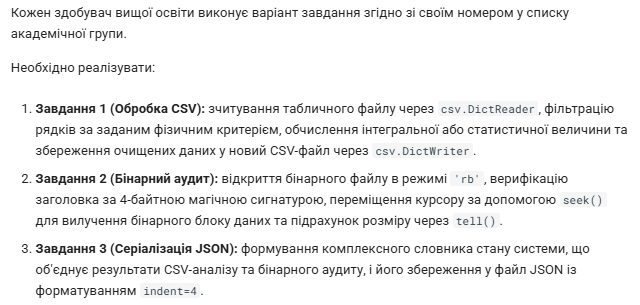

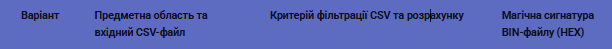
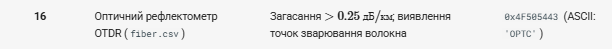

**Генерація вхідних тестових даних (`fiber.csv` та `otdr_trace.bin`)**

In [1]:
import csv
import struct
from pathlib import Path

lab10_dir = Path("lab10_otdr_variant16").resolve()
lab10_dir.mkdir(parents=True, exist_ok=True)

fiber_csv_path = lab10_dir / "fiber.csv"
bin_trace_path = lab10_dir / "otdr_trace.bin"

# 1. Формуємо вхідний файл fiber.csv (дані оптичного рефлектометра OTDR)
otdr_segments = [
    {"segment_id": "SEG-01", "distance_km": 0.42, "attenuation_db_km": 0.19, "reflectance_db": -52.4, "event_note": "Regular fiber"},
    {"segment_id": "SEG-02", "distance_km": 1.15, "attenuation_db_km": 0.34, "reflectance_db": -48.1, "event_note": "Fusion splice #1"},
    {"segment_id": "SEG-03", "distance_km": 2.08, "attenuation_db_km": 0.21, "reflectance_db": -54.0, "event_note": "Regular fiber"},
    {"segment_id": "SEG-04", "distance_km": 3.60, "attenuation_db_km": 0.47, "reflectance_db": -41.5, "event_note": "Mechanical splice #2"},
    {"segment_id": "SEG-05", "distance_km": 4.95, "attenuation_db_km": 0.25, "reflectance_db": -51.8, "event_note": "Threshold boundary"},
    {"segment_id": "SEG-06", "distance_km": 6.30, "attenuation_db_km": 0.62, "reflectance_db": -39.2, "event_note": "High-loss splice #3"},
    {"segment_id": "SEG-07", "distance_km": 7.80, "attenuation_db_km": 0.22, "reflectance_db": -53.1, "event_note": "Regular fiber"},
]

with fiber_csv_path.open("w", encoding="utf-8", newline="") as f_csv:
    fieldnames = ["segment_id", "distance_km", "attenuation_db_km", "reflectance_db", "event_note"]
    writer = csv.DictWriter(f_csv, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(otdr_segments)

# 2. Формуємо апаратний бінарний файл otdr_trace.bin:
# Заголовок (16 байт):
#   0..4   : магічна сигнатура b'OPTC' (0x4F505443)
#   4..6   : версія протоколу uint16 = 2
#   6..8   : довжина хвилі (нм) uint16 = 1550
#   8..12  : кількість відліків у блоці даних uint32 = 8
#   12..16 : резерв / CRC16 uint32 = 0x0000A1B2
# Корисне навантаження (payload) зі зміщення 16 байт: 8 значень float32 (рівні сигналу, дБ)
magic_bytes = b"OPTC"  # 0x4F505443
trace_samples = [-12.4, -12.9, -13.5, -14.8, -15.2, -16.9, -17.4, -18.1]
header_bytes = struct.pack(">4sHHII", magic_bytes, 2, 1550, len(trace_samples), 0x0000A1B2)
payload_bytes = struct.pack(f">{len(trace_samples)}f", *trace_samples)

with bin_trace_path.open("wb") as f_bin:
    f_bin.write(header_bytes)
    f_bin.write(payload_bytes)

print("Створено вхідний CSV:", fiber_csv_path)
print("Створено вхідний BIN:", bin_trace_path, f"({bin_trace_path.stat().st_size} байт)")


Створено вхідний CSV: D:\Діма\Програмування\Python\Приклади phyton\З університета\Python база\Labs\Lab10\lab10_otdr_variant16\fiber.csv
Створено вхідний BIN: D:\Діма\Програмування\Python\Приклади phyton\З університета\Python база\Labs\Lab10\lab10_otdr_variant16\otdr_trace.bin (48 байт)


**Завдання 1 — Обробка `fiber.csv` (`csv.DictReader` та `csv.DictWriter`)**

In [2]:
import csv
from pathlib import Path

lab10_dir = Path("lab10_otdr_variant16").resolve()
fiber_csv_path = lab10_dir / "fiber.csv"
filtered_csv_path = lab10_dir / "splices_detected.csv"

ATTENUATION_THRESHOLD = 0.25  # дБ/км

detected_splices = []
total_rows = 0
all_attenuations = []

with fiber_csv_path.open("r", encoding="utf-8", newline="") as f_in:
    reader = csv.DictReader(f_in)
    for row in reader:
        total_rows += 1
        dist_km = float(row["distance_km"])
        atten_db_km = float(row["attenuation_db_km"])
        refl_db = float(row["reflectance_db"])
        all_attenuations.append(atten_db_km)

        if atten_db_km > ATTENUATION_THRESHOLD:
            excess_db_km = round(atten_db_km - ATTENUATION_THRESHOLD, 4)
            detected_splices.append({
                "segment_id": row["segment_id"],
                "distance_km": f"{dist_km:.2f}",
                "attenuation_db_km": f"{atten_db_km:.2f}",
                "excess_over_threshold_db_km": f"{excess_db_km:.2f}",
                "reflectance_db": f"{refl_db:.1f}",
                "event_note": row["event_note"],
            })

output_fields = [
    "segment_id",
    "distance_km",
    "attenuation_db_km",
    "excess_over_threshold_db_km",
    "reflectance_db",
    "event_note",
]

with filtered_csv_path.open("w", encoding="utf-8", newline="") as f_out:
    writer = csv.DictWriter(f_out, fieldnames=output_fields)
    writer.writeheader()
    writer.writerows(detected_splices)

splice_attens = [float(item["attenuation_db_km"]) for item in detected_splices]
mean_splice_atten = sum(splice_attens) / len(splice_attens) if splice_attens else 0.0
max_splice_atten = max(splice_attens) if splice_attens else 0.0
mean_line_atten = sum(all_attenuations) / len(all_attenuations) if all_attenuations else 0.0

csv_analysis_summary = {
    "source_file": fiber_csv_path.name,
    "filtered_output_file": filtered_csv_path.name,
    "criterion": "attenuation_db_km > 0.25",
    "total_segments_scanned": total_rows,
    "splices_detected_count": len(detected_splices),
    "mean_line_attenuation_db_km": round(mean_line_atten, 4),
    "mean_splice_attenuation_db_km": round(mean_splice_atten, 4),
    "max_splice_attenuation_db_km": round(max_splice_atten, 4),
    "detected_splices": detected_splices,
}

print(f"Проскановано сегментів у {fiber_csv_path.name}: {total_rows}")
print(f"Виявлено точок зварювання (> {ATTENUATION_THRESHOLD} дБ/км): {len(detected_splices)}")
for sp in detected_splices:
    print(
        f"  - {sp['segment_id']} на {sp['distance_km']} км: "
        f"загасання = {sp['attenuation_db_km']} дБ/км (+{sp['excess_over_threshold_db_km']}), "
        f"відбиття = {sp['reflectance_db']} дБ [{sp['event_note']}]"
    )
print(f"Середнє загасання по лінії: {csv_analysis_summary['mean_line_attenuation_db_km']} дБ/км")
print(f"Середнє загасання у точках зварювання: {csv_analysis_summary['mean_splice_attenuation_db_km']} дБ/км")
print(f"Максимальне загасання: {csv_analysis_summary['max_splice_attenuation_db_km']} дБ/км")
print(f"Збережено очищений CSV: {filtered_csv_path}")


Проскановано сегментів у fiber.csv: 7
Виявлено точок зварювання (> 0.25 дБ/км): 3
  - SEG-02 на 1.15 км: загасання = 0.34 дБ/км (+0.09), відбиття = -48.1 дБ [Fusion splice #1]
  - SEG-04 на 3.60 км: загасання = 0.47 дБ/км (+0.22), відбиття = -41.5 дБ [Mechanical splice #2]
  - SEG-06 на 6.30 км: загасання = 0.62 дБ/км (+0.37), відбиття = -39.2 дБ [High-loss splice #3]
Середнє загасання по лінії: 0.3286 дБ/км
Середнє загасання у точках зварювання: 0.4767 дБ/км
Максимальне загасання: 0.62 дБ/км
Збережено очищений CSV: D:\Діма\Програмування\Python\Приклади phyton\З університета\Python база\Labs\Lab10\lab10_otdr_variant16\splices_detected.csv


**Завдання 2 — Бінарний аудит (`'rb'`, магічна сигнатура `0x4F505443` / `'OPTC'`, `seek()` та `tell()`)**

In [3]:
import os
import struct
from pathlib import Path

lab10_dir = Path("lab10_otdr_variant16").resolve()
bin_trace_path = lab10_dir / "otdr_trace.bin"

EXPECTED_MAGIC = b"OPTC"  # 0x4F505443
HEADER_SIZE = 16

with bin_trace_path.open("rb") as f_bin:
    # 1. Верифікація 4-байтної магічної сигнатури на початку файлу
    magic = f_bin.read(4)
    pos_after_magic = f_bin.tell()
    magic_hex = "0x" + magic.hex().upper()

    if magic != EXPECTED_MAGIC:
        raise ValueError(
            f"Невірна магічна сигнатура файлу: очікувалося 0x4F505443 ('OPTC'), отримано {magic_hex}"
        )

    # 2. Зчитування метаданих заголовка (байти 4..16)
    version, wavelength_nm, sample_count, crc_tag = struct.unpack(">HHII", f_bin.read(12))
    pos_after_header = f_bin.tell()

    # 3. Підрахунок загального розміру файлу через seek(0, os.SEEK_END) і tell()
    total_file_size = f_bin.seek(0, os.SEEK_END)
    payload_size_bytes = total_file_size - HEADER_SIZE

    # 4. Повернення курсору до початку корисного блоку даних (зміщення 16 байт)
    payload_start_pos = f_bin.seek(HEADER_SIZE, os.SEEK_SET)
    raw_payload = f_bin.read(sample_count * 4)
    pos_after_payload = f_bin.tell()

unpacked_samples = list(struct.unpack(f">{sample_count}f", raw_payload))
rounded_samples = [round(val, 2) for val in unpacked_samples]

binary_audit_summary = {
    "binary_file": bin_trace_path.name,
    "magic_signature_hex": magic_hex,
    "magic_signature_ascii": magic.decode("ascii"),
    "signature_valid": True,
    "protocol_version": version,
    "wavelength_nm": wavelength_nm,
    "crc_tag_hex": f"0x{crc_tag:08X}",
    "header_size_bytes": HEADER_SIZE,
    "payload_size_bytes": payload_size_bytes,
    "total_file_size_bytes": total_file_size,
    "cursor_positions": {
        "after_magic": pos_after_magic,
        "after_header": pos_after_header,
        "payload_start_seek": payload_start_pos,
        "after_payload_read": pos_after_payload,
    },
    "sample_count": sample_count,
    "trace_samples_db": rounded_samples,
}

print(f"Файл бінарного аудиту     : {bin_trace_path.name}")
print(f"Магічна сигнатура (HEX)   : {magic_hex} (ASCII: '{magic.decode('ascii')}') -> ВАЛІДНА")
print(f"Параметри заголовка       : версія={version}, довжина хвилі={wavelength_nm} нм, відліків={sample_count}")
print(f"Позиції курсору tell()    : після сигнатури={pos_after_magic}, після заголовка={pos_after_header}, кінець блоку={pos_after_payload}")
print(f"Розмір заголовка / блоку  : {HEADER_SIZE} Б / {payload_size_bytes} Б (усього {total_file_size} Б)")
print(f"Декодовані відліки (дБ)   : {rounded_samples}")


Файл бінарного аудиту     : otdr_trace.bin
Магічна сигнатура (HEX)   : 0x4F505443 (ASCII: 'OPTC') -> ВАЛІДНА
Параметри заголовка       : версія=2, довжина хвилі=1550 нм, відліків=8
Позиції курсору tell()    : після сигнатури=4, після заголовка=16, кінець блоку=48
Розмір заголовка / блоку  : 16 Б / 32 Б (усього 48 Б)
Декодовані відліки (дБ)   : [-12.4, -12.9, -13.5, -14.8, -15.2, -16.9, -17.4, -18.1]


**Завдання 3 — Персистентне збереження стану системи у JSON (`indent=4`)**

In [4]:
import json
from datetime import datetime
from pathlib import Path

lab10_dir = Path("lab10_otdr_variant16").resolve()
state_json_path = lab10_dir / "otdr_audit_state.json"

system_state = {
    "laboratory_work": 10,
    "variant": 16,
    "subsystem": "OTDR Optical Fiber Diagnostics",
    "generated_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "csv_analysis": csv_analysis_summary,
    "binary_audit": binary_audit_summary,
    "overall_status": (
        "WARNING_SPLICES_DETECTED"
        if csv_analysis_summary["splices_detected_count"] > 0
        else "NOMINAL"
    ),
}

with state_json_path.open("w", encoding="utf-8") as f_json:
    json.dump(system_state, f_json, indent=4, ensure_ascii=False)

# Перевірка цілісності серіализованого JSON-файлу зворотним зчитуванням
with state_json_path.open("r", encoding="utf-8") as f_json_check:
    reloaded_state = json.load(f_json_check)

assert reloaded_state == system_state, "Невідповідність після десеріалізації JSON!"

print(f"Стан системи збережено у: {state_json_path} ({state_json_path.stat().st_size} байт)")
print("\nВміст otdr_audit_state.json:")
print(state_json_path.read_text(encoding="utf-8"))


Стан системи збережено у: D:\Діма\Програмування\Python\Приклади phyton\З університета\Python база\Labs\Lab10\lab10_otdr_variant16\otdr_audit_state.json (2383 байт)

Вміст otdr_audit_state.json:
{
    "laboratory_work": 10,
    "variant": 16,
    "subsystem": "OTDR Optical Fiber Diagnostics",
    "generated_at": "2026-11-21 16:24:13",
    "csv_analysis": {
        "source_file": "fiber.csv",
        "filtered_output_file": "splices_detected.csv",
        "criterion": "attenuation_db_km > 0.25",
        "total_segments_scanned": 7,
        "splices_detected_count": 3,
        "mean_line_attenuation_db_km": 0.3286,
        "mean_splice_attenuation_db_km": 0.4767,
        "max_splice_attenuation_db_km": 0.62,
        "detected_splices": [
            {
                "segment_id": "SEG-02",
                "distance_km": "1.15",
                "attenuation_db_km": "0.34",
                "excess_over_threshold_db_km": "0.09",
                "reflectance_db": "-48.1",
                "ev

### **Висновки**

1. **Безпека менеджерів контексту (`with`):** Використання інструкції `with open(...)` гарантує детерміноване вивільнення файлових дескрипторів та скидання буферів на диск у методі `__exit__()` незалежно від того, чи завершився блок штатно, чи виник виняток під час обробки даних.
2. **Надійність CSV та JSON для персистентного збереження:** Модуль `csv` (`DictReader` / `DictWriter`) забезпечує структуровану табличну фільтрацію за іменами стовпців без прив'язки до їхнього порядку, а формат `JSON` із форматуванням `indent=4` дозволяє зберігати ієрархічні зведені звіти та стан системи у людиночитному і машинозчитуваному вигляді.
3. **Робота з бінарними потоками:** Відкриття файлів у режимі `'rb'`, верифікація 4-байтної магічної сигнатури (`0x4F505443` / `'OPTC'`) та точне позиціонування файлового курсору через `seek()` і `tell()` дають змогу надійно перевіряти формат апаратних дампів і вилучати бінарні блоки фіксованої структури.

### **Контрольні запитання**

1. **Як влаштований протокол менеджера контексту (__enter__ та __exit__) у мові Python? Чому використання інструкції with open(...) гарантує закриття файлу навіть у разі збудження винятку ZeroDivisionError під час запису?**
Протокол менеджера контексту складається з двох магічних методів: `__enter__(self)` (виконується при вході в блок `with` і повертає ресурс, наприклад файловий об'єкт) та `__exit__(self, exc_type, exc_val, exc_tb)` (завжди викликається при виході з блоку `with`). Якщо всередині блоку виникає `ZeroDivisionError`, інтерпретатор усе одно викликає `__exit__()`, де файловий об'єкт виконує `flush()` і `close()`, а потім (оскільки `__exit__` повертає `False`/`None`) виняток передається далі вгору по стеку.

2. **У чому полягає різниця між текстовим ('r', 'w') та бінарним ('rb', 'wb') режимами відкриття файлів? Чому в текстовому режимі використання довільних зміщень у методі file.seek(offset) є забороненим для багатобайтових кодувань UTF-8?**
У текстовому режимі (`'r'`, `'w'`) Python працює з рядками `str`, автоматично кодує/декодує байти (наприклад, у UTF-8) та нормалізує символи кінця рядка (`\r\n` ↔ `\n`). У бінарному режимі (`'rb'`, `'wb'`) операції виконуються напряму із сирими байтами `bytes` без будь-яких перетворень. У UTF-8 один символ може займати від 1 до 4 байтів, тому довільне байтове зміщення в `seek(offset)` у текстовому потоці може потрапити всередину багатобайтового символу і зламати декодування (дозволено лише `0` або значення, раніше повернене `tell()`).

3. **Поясніть призначення та інженерне використання магічних сигнатур (magic numbers) у бінарних файлах. Що повертає метод file.seek(0, os.SEEK_END)?**
Магічна сигнатура — це фіксована послідовність байтів на початку бінарного файлу (наприклад, `0x4F505443` / `'OPTC'`), яка дозволяє програмі швидко перевірити справжній формат і цілісність файлу до парсингу корисних даних, не покладаючись лише на розширення імені. Виклик `file.seek(0, os.SEEK_END)` переміщує курсор на `0` байтів відносно кінця файлу і повертає нову абсолютну позицію від початку файлу в байтах, тобто повний розмір файлу.

4. **Чим відрізняються методи модуля json: json.dump() від json.dumps() та json.load() від json.loads()? Які типи даних Python не підтримують пряму серіалізацію у формат JSON без власного енкодера?**
`json.dump(obj, fp)` серіалізує об'єкт безпосередньо у файловий потік `fp`, а `json.dumps(obj)` повертає JSON-рядок `str` у пам'яті. Відповідно `json.load(fp)` читає і парсить JSON із файлового потоку `fp`, а `json.loads(s)` — із рядка `str` (або `bytes`). Пряму серіалізацію без власного `JSONEncoder` (або параметра `default`) не підтримують множини `set`/`frozenset`, кортежі як окремий тип (перетворюються на JSON-масив), `bytes`/`bytearray`, `datetime`/`date`, `Decimal`, `complex`, об'єкти `Path` та користувацькі класи.

5. **Опишіть переваги використання класу csv.DictReader над базовим csv.reader при роботі з табличними даними, що мають заголовки стовпців.**
`csv.DictReader` автоматично зчитує перший рядок заголовків як ключі і повертає кожен наступний запис у вигляді словника `dict`. Це дає змогу звертатися до полів за зрозумілими іменами (`row['attenuation_db_km']`) замість числових індексів (`row[2]`), підвищує читабельність коду та робить парсер стійким до зміни порядку стовпців у вхідному CSV-файлі.

6. **Що таке системна буферизація введення-виведення, і як параметр buffering функції open() впливає на продуктивність запису великих масивів телеметрії?**
Системна буферизація накопичує дані в проміжному буфері оперативної пам'яті перед виконанням дорогого системного виклику (`write`) до диска/ОС. Параметр `buffering` у `open()` керує цим режимом: `buffering=0` (тільки для бінарних файлів) вимикає буферизацію (кожен запис одразу йде в ОС — мінімальна затримка, але найнижча швидкість), `buffering=1` вмикає порядкову буферизацію для текстових файлів, а передача великого цілого значення (наприклад, `buffering=65536` або `1048576` байт) суттєво зменшує кількість системних викликів і різко підвищує пропускну здатність під час запису великих масивів телеметрії.